In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.pipeline import Pipeline
# Preprocesamiento
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Selección de características
from sklearn.feature_selection import SequentialFeatureSelector

# Reducción de dimensionalidad
from sklearn.decomposition import PCA

# Model selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

# Métricas
from sklearn.metrics import accuracy_score, classification_report, recall_score, roc_auc_score, roc_curve, auc, confusion_matrix, f1_score

# Pipelines y balanceo
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline 
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from sklearn.cluster import KMeans



In [81]:
churn_train = pd.read_csv('churn_train_clean.csv')
churn_test = pd.read_csv('churn_test_clean.csv')
X_train = churn_train.drop(columns='Churn Value')
Y_train = churn_train['Churn Value']
X_test = churn_test.drop(columns='Churn Value')
Y_test = churn_test['Churn Value']

In [82]:
numerical_cols = ["Total Charges", "Monthly Charges", "Tenure Months", "CLTV"]
categorical_cols = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method"
]

# RANDOM FOREST

In [83]:
# Preprocesador para las transformaciones de columnas

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


# Pipeline con el preprocesador, el balanceo y el modelo

pipeline_rf = Pipeline([
    ("preprocessor", preprocessor),         # transformar datos
    ("oversample", RandomOverSampler(random_state=10)),  # balancear clases
    ("rf", RandomForestClassifier(random_state=10))
])


# Parámetros a probar por el modelo
param_grid = {
    "rf__n_estimators": [100, 200, 300],
    "rf__max_depth": [2, 4, 6, 8]
    }

#Grid search
grid_search = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid,
    scoring="f1",
    cv=4,
    verbose=1,
    n_jobs=-1
)
print("Ejecutando GridSearchCV...")
grid_search.fit(X_train, Y_train)
print("GridSearch completo.\n")

print("Mejores parámetros encontrados:")
print(grid_search.best_params_)

print(f"\nMejor score CV (F1): {grid_search.best_score_:.4f}")


#Evaluación final en test
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("\n=== REPORTE FINAL EN TEST ===")
print(classification_report(Y_test, y_pred))

final_recall = recall_score(Y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando GridSearchCV...
Fitting 4 folds for each of 12 candidates, totalling 48 fits
GridSearch completo.

Mejores parámetros encontrados:
{'rf__max_depth': 8, 'rf__n_estimators': 300}

Mejor score CV (F1): 0.6440

=== REPORTE FINAL EN TEST ===
              precision    recall  f1-score   support

           0       0.91      0.75      0.82      1294
           1       0.54      0.80      0.64       467

    accuracy                           0.76      1761
   macro avg       0.72      0.77      0.73      1761
weighted avg       0.81      0.76      0.77      1761

Recall Final en TEST: 0.7987


# XGBOOST

In [84]:
# Preprocesador para las transformaciones de columnas

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


# Pipeline con el preprocesador, el balanceo y el modelo

pipeline_xgb = Pipeline([
    ("preprocessor", preprocessor),        
    ("oversample", RandomOverSampler(random_state=10)),  
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=10,
        n_jobs=-1
    ))
])

# Parámetros a probar por el modelo
param_grid = {
    "xgb__n_estimators": [100, 200, 300],
    "xgb__max_depth": [2, 4, 6, 8],
    "xgb__learning_rate": [0.05, 0.1, 0.2],

}


#Grid search

grid_search = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid,
    scoring="recall",
    cv=4,
    verbose=1,
    n_jobs=-1
)

print("Ejecutando GridSearchCV...")
grid_search.fit(X_train, Y_train)
print("GridSearch completo.\n")

print("Mejores parámetros encontrados:")
print(grid_search.best_params_)

print(f"\nMejor score CV (Recall): {grid_search.best_score_:.4f}")



#Evaluación final en test

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("\n=== REPORTE FINAL EN TEST ===")
print(classification_report(Y_test, y_pred))

final_recall = recall_score(Y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando GridSearchCV...
Fitting 4 folds for each of 36 candidates, totalling 144 fits
GridSearch completo.

Mejores parámetros encontrados:
{'xgb__learning_rate': 0.05, 'xgb__max_depth': 2, 'xgb__n_estimators': 100}

Mejor score CV (Recall): 0.8096

=== REPORTE FINAL EN TEST ===
              precision    recall  f1-score   support

           0       0.92      0.72      0.81      1294
           1       0.52      0.83      0.64       467

    accuracy                           0.75      1761
   macro avg       0.72      0.77      0.72      1761
weighted avg       0.81      0.75      0.76      1761

Recall Final en TEST: 0.8266


# Naive Bayes Gaussiano

In [85]:
# Procesador de columnas

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

# Pipeline con preprocesador, balanceo y modelo

pipeline_nb = Pipeline([
    ("preprocessor", preprocessor),
    ("undersampler", RandomOverSampler(random_state=10)),
    ("nb", GaussianNB())
])


print("Ejecutando Cross-Validation (CV=5)...")
cv_scores = cross_val_score(
    pipeline_nb, 
    X_train,      # aquí usamos directamente X_train
    Y_train,
    cv=5, 
    scoring='f1', 
    n_jobs=-1
)

print(f"F1 promedio en CV: {cv_scores.mean():.4f}")
print(f"Desviación estándar en CV: {cv_scores.std():.4f}")

# ============================================================
# Entrenamiento final sobre todo el train
# ============================================================

print("\nEntrenando GaussianNB con oversampling sobre todo el train...")
pipeline_nb.fit(X_train, Y_train)
print("Entrenamiento completado.")

# ============================================================
# Predicción en test
# ============================================================

y_pred = pipeline_nb.predict(X_test)

print("\n=== REPORTE FINAL ===")
print(classification_report(Y_test, y_pred))

final_recall = recall_score(Y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando Cross-Validation (CV=5)...
F1 promedio en CV: 0.6262
Desviación estándar en CV: 0.0164

Entrenando GaussianNB con oversampling sobre todo el train...
Entrenamiento completado.

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1294
           1       0.52      0.79      0.63       467

    accuracy                           0.75      1761
   macro avg       0.71      0.76      0.72      1761
weighted avg       0.80      0.75      0.76      1761

Recall Final en TEST: 0.7944


# Regresión logística

In [86]:

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


pipeline_nb = Pipeline([
    ("preprocessor", preprocessor),
    ("undersampler", RandomOverSampler(random_state=10)),
    ("nb", LogisticRegression(random_state=10))
])


print("Ejecutando Cross-Validation (CV=5)...")
cv_scores = cross_val_score(
    pipeline_nb, 
    X_train,     
    Y_train,
    cv=5, 
    scoring='f1', 
    n_jobs=-1
)

print(f"F1 promedio en CV: {cv_scores.mean():.4f}")
print(f"Desviación estándar en CV: {cv_scores.std():.4f}")

# ============================================================
# Entrenamiento final sobre todo el train
# ============================================================

print("\nEntrenando regrersion logistica con oversampling sobre todo el train...")
pipeline_nb.fit(X_train, Y_train)
print("Entrenamiento completado.")

# ============================================================
# Predicción en test
# ============================================================

y_pred = pipeline_nb.predict(X_test)

print("\n=== REPORTE FINAL ===")
print(classification_report(Y_test, y_pred))

final_recall = recall_score(Y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando Cross-Validation (CV=5)...
F1 promedio en CV: 0.6406
Desviación estándar en CV: 0.0129

Entrenando regrersion logistica con oversampling sobre todo el train...
Entrenamiento completado.

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1294
           1       0.52      0.80      0.63       467

    accuracy                           0.75      1761
   macro avg       0.71      0.76      0.72      1761
weighted avg       0.81      0.75      0.76      1761

Recall Final en TEST: 0.7966


## A continuación, vamos a **preparar los datos** para aplicar **K-Means** y, después, usar el **elbow method** para decidir un número razonable de clusters `k`.  




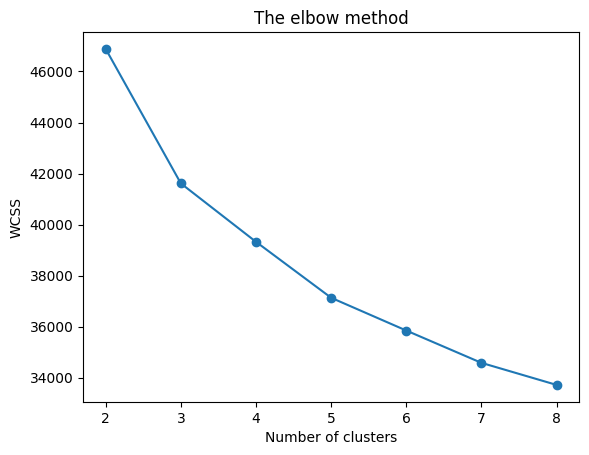

In [87]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans

X_cluster = X_train.copy()  

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])



X_trans = preprocessor.fit_transform(X_cluster)

K = range(2, 9)
wcss = []

for k in K:
    model = KMeans(n_clusters=k, random_state=0, n_init="auto").fit(X_trans)
    wcss.append(model.inertia_)

plt.plot(list(K), wcss, marker="o")
plt.title("The elbow method")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()


In [88]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd

scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=10, n_init=10)
    labels = km.fit_predict(X_trans) 
    scores.append({
        "k": k,
        "silhouette": silhouette_score(X_trans, labels),
        "calinski_harabasz": calinski_harabasz_score(X_trans, labels),
        "davies_bouldin": davies_bouldin_score(X_trans, labels),
        "inertia": km.inertia_
    })

pd.DataFrame(scores)


,k,silhouette,calinski_harabasz,davies_bouldin,inertia
0,2,0.212546,1520.663964,1.776604,46884.521970
1,3,0.160835,1190.771206,2.041810,41614.013602
2,4,0.155080,962.668158,2.268234,39030.728560
3,5,0.131437,826.298998,2.109386,37130.906459
4,6,0.120738,727.803732,2.288095,35737.931822
5,7,0.113134,656.792730,2.363988,34565.143490
6,8,0.100251,597.934270,2.413604,33667.989993


Las métricas internas del clustering sugieren que la partición más “limpia” en términos estadísticos sería k=2, ya que maximiza la separación entre grupos. Sin embargo, convendría segmentarlo en más grupos para así tener una distinción aún más clara de los grupos con mayor probabilidad de churn. Por tanto, vamos a revisar cual de los valores de `k` tiene una menor desviación típica en las distintas inicializaciones de sus inercias (ya que dependiendo de la inicialización, estas pueden caer en un mínimo local)

In [89]:
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd

rows = []
for k in range(2, 13):
    inertias = []
    for seed in range(10):
        km = KMeans(n_clusters=k, random_state=seed, n_init=10)
        km.fit(X_trans)
        inertias.append(km.inertia_)
    rows.append({
        "k": k,
        "inertia_mean": np.mean(inertias),
        "inertia_std": np.std(inertias)
    })

pd.DataFrame(rows).sort_values("k")


,k,inertia_mean,inertia_std
0,2,46884.521970,7.275958e-12
1,3,41613.945652,9.032810e-02
2,4,39030.979631,2.888050e-01
3,5,37130.793300,2.269362e-01
4,6,35748.726216,3.249700e+01
5,7,34565.605084,3.525445e-01
6,8,33667.616094,6.053136e-01
7,9,32923.909489,1.500274e+00
8,10,32246.978111,3.145080e+01
9,11,31692.606316,2.953508e+01


Finalmente, optamos por un valor de  k = 5 ya que, aunque k = 2 es el valor más estable, ofrece una segmentación demasiado general. En cambio, k = 5 mantiene una estabilidad aceptable (sin la inestabilidad observada en k = 6), se alinea con el método del codo y proporciona la granularidad necesaria para diferenciar perfiles de clientes de forma útil.

In [90]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=0, n_init="auto")
clusters = kmeans.fit_predict(X_trans)

res = pd.DataFrame({
    "cluster": clusters,
    "churn": Y_train.values  
})

print("Tamaño por cluster:")
print(res["cluster"].value_counts().sort_index(), "\n")

print("Churn rate por cluster (ordenado):")
print(res.groupby("cluster")["churn"].mean().sort_values(ascending=False), "\n")

print("Tabla co<mpleta:")
tabla = res.groupby("cluster").agg(n=("churn","size"), churn_rate=("churn","mean"), churners=("churn","sum")).sort_values("churn_rate", ascending=False)

tabla


Tamaño por cluster:
cluster
0    1490
1     632
2     817
3    1244
4    1099
Name: count, dtype: int64 

Churn rate por cluster (ordenado):
cluster
0    0.552349
3    0.278135
4    0.150136
2    0.074663
1    0.011076
Name: churn, dtype: float64 

Tabla co<mpleta:


,n,churn_rate,churners
cluster,,,
0,1490,0.552349,823
3,1244,0.278135,346
4,1099,0.150136,165
2,817,0.074663,61
1,632,0.011076,7


## Interpretación de los clusters (k = 5)

Con los clusters ya definidos, el objetivo ahora es **entender qué tipo de clientes hay en cada grupo**.  
Para ello, vamos a perfilar cada cluster con tres piezas de información:

- **Tamaño del cluster y churn rate** (riesgo de fuga).
- **Variables numéricas**: medias y medianas por cluster.
- **Variables categóricas**: categorías más frecuentes por cluster.

Por tanto, analizaremos las características de los clusters 0 y 3, ya que son los que tienen un mayor churn rate (55% y 28%)

In [91]:
clusters = KMeans(n_clusters=5, random_state=0, n_init="auto").fit_predict(X_trans)

dfc = X_train.copy()
dfc["cluster"] = clusters

cls = [0, 3]  # clusters de mayor churn

rows = []
for c in cls:
    d = dfc[dfc["cluster"] == c]
    for col in categorical_cols:

        #Calculamos cuantas veces aparece esa categoría en ese cluster
        vc = d[col].value_counts(dropna=False)

        #Categoría top
        top = vc.index[0]

        #Porcentaje en el cluster
        pct = vc.iloc[0] / vc.sum() * 100
        rows.append({
            "cluster": c,
            "feature": col,
            "top_category": top,
            "pct_in_cluster": round(pct, 1)
        })

resumen = (pd.DataFrame(rows)
                  .sort_values(["cluster", "pct_in_cluster"], ascending=[True, False])
                  .groupby("cluster")
                  .head(10))  # Elegimos las 5 categorías que aparezcan más en ese cluster
display(resumen)


,cluster,feature,top_category,pct_in_cluster
4,0,Phone Service,Yes,99.7
13,0,Contract,Month-to-month,94.8
6,0,Internet Service,Fiber optic,92.9
3,0,Dependents,No,89.9
7,0,Online Security,No,84.9
10,0,Tech Support,No,83.1
14,0,Paperless Billing,Yes,80.8
8,0,Online Backup,No,73.3
1,0,Senior Citizen,No,73.2
9,0,Device Protection,No,71.5


## Interpretación (Top 10) de los clusters 0 y 3

Al mirar las Top 10 categorías, se confirma que ambos segmentos de mayor churn son muy homogéneos (muchos cercanos al 90%), por tanto, los rasgos que aparecen son realmente representativos.

- **Cluster 0 (churn muy alto):** predominan clientes con contrato month-to-month, fibra óptica y poca contratación de servicios de seguridad y protección, además de un perfil sin dependientes. Es un segmento con baja permanencia en la empresa, coherente con mayor churn.

- **Cluster 3 (churn alto):** perfil de uso más “básico”, con muchos No en servicios extra (streaming, device protection, múltiples líneas). Es un segmento con un bajo uso de servicios complementarios, lo que suele asociarse a menor fidelización.

En resumen: los dos clusters comparten **baja adopción de extras**, pero el **cluster 0** destaca especialmente por la **baja permanencia (month-to-month)**.
